## Lab 2

### Part 3. Poetry generation

Взяты сонеты Шекспира из sonnets.txt. Сравниваются посимвольные RNN и LSTM, потом генерируется текст при разных температурах.

In [1]:
from pathlib import Path
from copy import deepcopy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
print('Устройство:', device, '| PyTorch:', torch.__version__)

def loader(x, y, batch_size=256, shuffle=False, seed=SEED):
    return DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed), num_workers=0)

import string
import torch.nn.functional as F

Устройство: cpu | PyTorch: 2.15.0+cpu


### Data loading: Shakespeare

Shakespeare sonnets are awailable at this [link](http://www.gutenberg.org/ebooks/1041?msg=welcome_stranger). In addition, they are stored in the same directory as this notebook (`sonnetes.txt`). Simple preprocessing is already done for you in the next cell: all technical info is dropped.

In [2]:
with open('sonnets.txt', encoding='utf-8') as stream:
    lines = stream.readlines()
lines = lines[45:-368]
assert len(lines) == 2616
print('Строк после удаления служебной информации:', len(lines))

Строк после удаления служебной информации: 2616


In opposite to the in-class practice, this time we want to predict complex text. Let's reduce the complexity of the task and lowercase all the symbols.

Now variable `text` is a list of strings. Join all the strings into one and lowercase it.

In [3]:
text = ''.join(lines).lower()
assert len(text) == 100225
assert not (set(text) & set(string.ascii_uppercase))
print('Символов:', len(text))

Символов: 100225


Put all the characters, that you've seen in the text, into variable `tokens`.

In [6]:
tokens = sorted(set(text))
print('Размер словаря:', len(tokens))

Размер словаря: 38


Create dictionary `token_to_idx = {<char>: <index>}` and dictionary `idx_to_token = {<index>: <char>}`

In [7]:
token_to_idx = {token: i for i, token in enumerate(tokens)}
idx_to_token = {i: token for token, i in token_to_idx.items()}
assert all(idx_to_token[token_to_idx[t]] == t for t in tokens)

В словаре 38 символов, на вход сети они подаются в one-hot. Первые 139 сонетов идут в train, последние 15 в validation. Окна по 100 символов не заходят через границу между ними.

### Building the model

Now we want to build and train recurrent neural net which would be able to something similar to Shakespeare's poetry.

Let's use vanilla RNN, similar to the one created during the lesson.

In [8]:
import re

sonnet_starts = list(re.finditer(r'(?m)^  [ivxlcdm]+\s*$', text))
# срез lines[45:] из задания отрезает номер первого сонета, поэтому номеров 153, а не 154
assert len(sonnet_starts) == 153
split = sonnet_starts[-15].start()
encoded = torch.tensor([token_to_idx[c] for c in text], dtype=torch.long)
train_text, val_text = encoded[:split], encoded[split:]
SEQ_LENGTH, MAX_LENGTH, HIDDEN_SIZE = 100, 500, 128

def language_batches(data, training, seed=SEED):
    # на train окна каждую эпоху начинаются со случайного сдвига, на validation сдвиг 0
    generator = torch.Generator().manual_seed(seed)
    offset = int(torch.randint(SEQ_LENGTH, (1,), generator=generator)) if training else 0
    n = (len(data) - offset - 1) // SEQ_LENGTH
    x = data[offset:offset + n * SEQ_LENGTH].reshape(n, SEQ_LENGTH)
    y = data[offset + 1:offset + 1 + n * SEQ_LENGTH].reshape(n, SEQ_LENGTH)
    return loader(x, y, batch_size=64, shuffle=training, seed=seed)

class CharModel(nn.Module):
    def __init__(self, kind='RNN', vocab_size=len(tokens), hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.kind, self.vocab_size, self.hidden_size = kind, vocab_size, hidden_size
        recurrent = nn.RNN if kind == 'RNN' else nn.LSTM
        self.recurrent = recurrent(vocab_size, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, vocab_size)

    def forward(self, indices, state=None):
        one_hot = F.one_hot(indices, num_classes=self.vocab_size).float()
        hidden, state = self.recurrent(one_hot, state)
        return self.output(hidden), state

@torch.no_grad()
def language_loss(model, data):
    model.eval()
    total, count = 0.0, 0
    for x, y in language_batches(data, False):
        logits, _ = model(x.to(device))
        total += F.cross_entropy(logits.flatten(0, 1), y.to(device).flatten(), reduction='sum').item()
        count += y.numel()
    return total / count

def train_language(kind, epochs=55):
    set_seed()
    model = CharModel(kind).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs, eta_min=0.0003)
    history, best_loss, best_state, best_epoch = [], float('inf'), None, 0
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in language_batches(train_text, True, seed=SEED + epoch):
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(x.to(device))
            loss = F.cross_entropy(logits.flatten(0, 1), y.to(device).flatten())
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        tr, va = language_loss(model, train_text), language_loss(model, val_text)
        history.append({'epoch': epoch, 'train_loss': tr, 'val_loss': va})
        if va < best_loss:
            best_loss, best_state, best_epoch = va, deepcopy(model.state_dict()), epoch
        scheduler.step()
        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            print(f'{kind}, эпоха {epoch}: train CE={tr:.4f}, val CE={va:.4f}', flush=True)
    model.load_state_dict(best_state)
    print(kind, '| выбранная эпоха:', best_epoch, '| val perplexity:', np.exp(best_loss))
    history = pd.DataFrame(history)
    return model, history, best_epoch

print('Train / validation:', len(train_text), len(val_text), '| сонетов: 139 / 15')
rnn, rnn_history, rnn_epoch = train_language('RNN')

Train / validation: 90577 9648 | сонетов: 139 / 15


RNN, эпоха 1: train CE=2.9593, val CE=2.9509


RNN, эпоха 10: train CE=2.0981, val CE=2.1311


RNN, эпоха 20: train CE=1.9157, val CE=1.9829


RNN, эпоха 30: train CE=1.8156, val CE=1.9109


RNN, эпоха 40: train CE=1.7642, val CE=1.8714


RNN, эпоха 50: train CE=1.7416, val CE=1.8549


RNN, эпоха 55: train CE=1.7356, val CE=1.8514


RNN | выбранная эпоха: 55 | val perplexity: 6.368861631541235


Plot the loss function (axis X: number of epochs, axis Y: loss function).

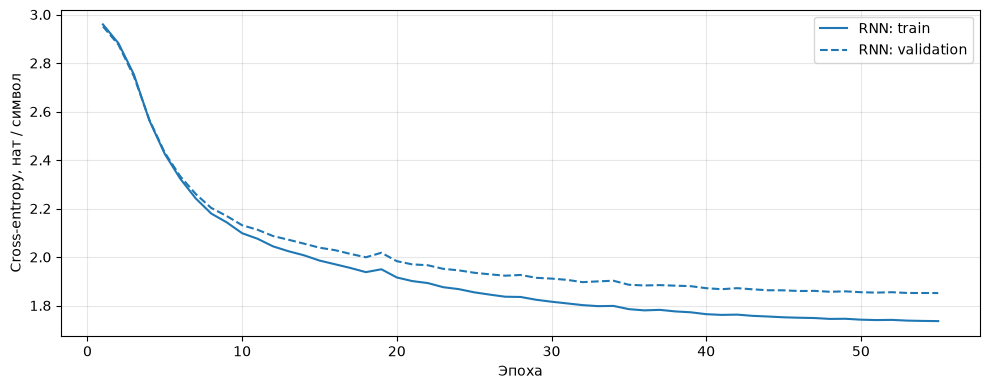

In [9]:
def plot_language(histories):
    plt.figure(figsize=(10, 4))
    for name, history in histories.items():
        line, = plt.plot(history.epoch, history.train_loss, label=name + ': train')
        plt.plot(history.epoch, history.val_loss, '--', color=line.get_color(), label=name + ': validation')
    plt.xlabel('Эпоха')
    plt.ylabel('Cross-entropy, нат / символ')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_language({'RNN': rnn_history})

In [10]:
@torch.no_grad()
def generate_sample(char_rnn, seed_phrase='shall i compare thee', max_length=MAX_LENGTH,
                    temperature=1.0, seed=SEED):
    char_rnn.eval()
    model_device = next(char_rnn.parameters()).device
    generator = torch.Generator(device=model_device).manual_seed(seed)
    prefix = torch.tensor([[token_to_idx[c] for c in seed_phrase]], device=model_device)
    logits, state = char_rnn(prefix)
    result = list(seed_phrase)
    for _ in range(max_length - len(seed_phrase)):
        probabilities = F.softmax(logits[:, -1] / temperature, dim=-1)
        next_idx = torch.multinomial(probabilities, 1, generator=generator)
        result.append(idx_to_token[next_idx.item()])
        logits, state = char_rnn(next_idx, state)
    return ''.join(result)

In [11]:
print(generate_sample(rnn, temperature=0.5))

shall i compare thee thou thou the will and beart for my love
  and diss the meare wat leve, the fores dises forther mest,
  in the rost hear in the thear wher fare, beart be thee,
    the wert and hast me thou keven my pors and sece come the sull in thy busters got.

  lxix

  when with thou mese in the pint of she that thee tree,
  which in the erest doth summer thou shall with gave,
    to seave to the parise for that my meile the hasting all brame.
    and thee in thy seall sond sill ant san


### More poetic model

Let's use LSTM instead of vanilla RNN and compare the results.

Plot the loss function of the number of epochs. Does the final loss become better?

LSTM, эпоха 1: train CE=2.9823, val CE=2.9789


LSTM, эпоха 10: train CE=2.1811, val CE=2.2010


LSTM, эпоха 20: train CE=1.9547, val CE=1.9972


LSTM, эпоха 30: train CE=1.8484, val CE=1.9113


LSTM, эпоха 40: train CE=1.7947, val CE=1.8682


LSTM, эпоха 50: train CE=1.7721, val CE=1.8528


LSTM, эпоха 55: train CE=1.7657, val CE=1.8475


LSTM | выбранная эпоха: 55 | val perplexity: 6.343915954184124


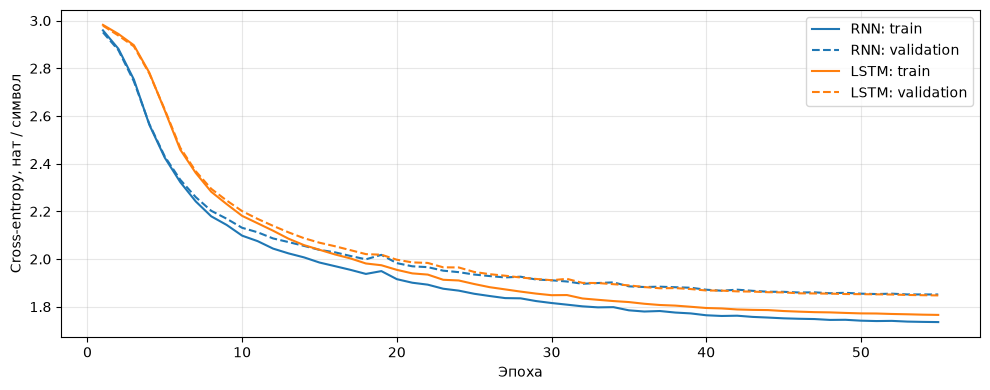

,model,parameters,epoch,val_CE,val_perplexity
0,RNN,26406,55,1.8514,6.3689
1,LSTM,90918,55,1.8475,6.3439


In [12]:
lstm, lstm_history, lstm_epoch = train_language('LSTM')
plot_language({'RNN': rnn_history, 'LSTM': lstm_history})
language_comparison = pd.DataFrame([
    {'model': name, 'parameters': sum(p.numel() for p in model.parameters()),
     'epoch': epoch, 'val_CE': language_loss(model, val_text),
     'val_perplexity': np.exp(language_loss(model, val_text))}
    for name, model, epoch in [('RNN', rnn, rnn_epoch), ('LSTM', lstm, lstm_epoch)]])
display(language_comparison.round(4))

Generate text using the trained net with different `temperature` parameter: `[0.1, 0.2, 0.5, 1.0, 2.0]`.

Evaluate the results visually, try to interpret them.

In [13]:
for temperature in [0.1, 0.2, 0.5, 1.0, 2.0]:
    print(f'\n--- temperature = {temperature} ---')
    print(generate_sample(lstm, temperature=temperature))


--- temperature = 0.1 ---
shall i compare thee the stare,
  and the sear the sealt the seart the seart the seate the seart the seart the stare,
    the sear the seal the start the sear the store the store,
    the sear the sealt the seart the seart the seart the seart of the seart of the seart of the seart the seat
  the sear the sight the seart the seart the stare,
  and the seart the seart the seart the stell the sear stare,
  and the sear the sear the stell the seart the sead the stare the stare,
  and the sear the se

--- temperature = 0.2 ---
shall i compare thee the stare
  the sand the with the shall the stell so mest and with the seall the seal
  the seat the sear stall the have in the store,
    and the seat in the fore the seat and thee with thee the start stall the seart the sear in the sead stell the store so mest
  and the sear the seed the sill stall the stell so mest in the sear the sand,
  and in the with the with the seall the seart the seart the say seed
    and the 


--- temperature = 0.5 ---
shall i compare thee thou thou the with shang,
    the chath dees the poors of are with thes love
  wild hes love that the pare,
  a dit he of all thes mest the dear my me in thee frore my heart and the seath doke.
    and shath se preaver shas for my see,
    the thou my for the broud, and thee be the seace the sice,
    so ble my shenst so ceartes with the hame for there with the erese my for the doth are the ends that ay seilf the hasting stall sher.
  s the when the bute as and of thin thes 

--- temperature = 1.0 ---
shall i compare thee tay jot,;
  luce and think, by ar you widemuge, choort of freew.
  'vis thenerust diles list, my force ther is myst hee hisllt,
  om with to draikse t in thou frord my heartar'y,
  the wind keves my pors azsof crich'd the sofrecoucquers dest
  thou my for clestres', and thee being to aigh thiss of all sooul live seest,
  nead be wime the hemkeft dainss with theme to smeno's leak,
   are biskefor that ay meile mes i frill


--- temperature = 2.0 ---
shall i compare thee kadnjtt,;
t luce.

   diios! frar yo awid, ques choort ovefre waes
' is olllewuct dileswllstiert forcortin,
  arcstyhweoliyllts! somey sw ard,r' eper  ii hitjvemy demed makna;
y,
 xxve

  foke newmrepc-s azsof quich'r thyur-freime,qyerusd brvghtash'd;
  ilcles!d wnat, -bi,
! c incr eekigw gfissc?,';  ksoy lrlive sensoss-wne fies di elk
  un wafted, yos we ind gadisof muno's leak,
  saupi i'le orgwele ny meile's so; f!il
  to br arrdi ey if remem go not e
  h?in os kbi,
  fvo


2612

### Saving and loading models

Модель сохраняется на диск и загружается в новую сеть. Чтобы проверить загрузку, текст генерируется до и после с одним и тем же seed.

In [14]:
checkpoint = ARTIFACTS / 'poetry_lstm.pt'
torch.save({'state_dict': lstm.cpu().state_dict(), 'tokens': tokens, 'kind': 'LSTM',
            'hidden_size': HIDDEN_SIZE, 'selected_epoch': lstm_epoch}, checkpoint)
lstm.to(device)
saved = torch.load(checkpoint, map_location=device, weights_only=True)
assert saved['tokens'] == tokens
restored = CharModel(saved['kind'], len(saved['tokens']), saved['hidden_size']).to(device)
restored.load_state_dict(saved['state_dict'])
before = generate_sample(lstm, temperature=0.5, seed=123)
after = generate_sample(restored, temperature=0.5, seed=123)
assert before == after
print('Генерация до и после загрузки совпадает при фиксированном seed.')
print(after)

Генерация до и после загрузки совпадает при фиксированном seed.
shall i compare thee and all then my live,
  where thou thou his for the gare to the fart ay wout
  the with love, shace si fis live thou have the praise,
  thy prouds the wich share sen thy slead.
    whis thy worth shath the songred then live the love, thee shill and and in to herure.
    thy hesteres geart and thee the seaty in the pore,
  the eart far the seart mase heart in the speerst.

  xxxii

  then love death as in the chald prods not me thee live thee my lays me the semang,
  whin tho


### References
1. [Исходное задание](https://github.com/girafe-ai/ml-course/tree/23f_basic/homeworks/lab02_deep_learning)
2. [PyTorch: RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html)
3. [PyTorch: LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html)
4. [PyTorch: сохранение и загрузка моделей](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html)

### Выводы

Обе модели обучались 55 эпох, hidden size 128. У RNN 26 406 параметров, у LSTM 90 918. Лучшей у обеих оказалась последняя эпоха.

| Модель | Validation CE | Perplexity |
|---|---:|---:|
| RNN | 1.8514 | 6.369 |
| LSTM | 1.8475 | 6.344 |

У LSTM лосс чуть ниже, но разница очень маленькая, хотя параметров у неё примерно в 3.4 раза больше.

При температуре 0.1 и 0.2 модель повторяет одно и то же (the seart, the sear). При 0.5 текст разнообразнее, появляются настоящие слова вроде love и heart, но много и выдуманных. При 1.0 слова ещё узнаются, но выдуманных уже больше половины. При 2.0 получается почти случайный набор букв и знаков. Модель выучила отступы, переносы строк и номера сонетов, но осмысленных стихов не получилось.

В artifacts/poetry_lstm.pt сохранены веса LSTM, словарь и размер скрытого слоя. Текст до сохранения и после загрузки совпал.